# Figure 1f. Recovery of global trans-regulatory effects

We compared TransMap-global with ARCHIE using the 60-variant, nine-gene network in Figure 1e. Curves show the mean of interpolated pair-level precision-recall curves across 1,000 independent simulations at each per-SNP *trans*-heritability level. Precision and recall are defined against the 160 true variant-gene pairs; the plotted mean curves are not used to compute the mean replicate AUPRC.

Across the three effect levels, mean replicate AUPRC was 18.2%-22.5% higher for TransMap-global. At 80% precision, the largest difference in recall between the mean curves was 0.41. The figure displays the matched TransMap-global and ARCHIE comparators; an additional ARCHIE code-implementation benchmark in the source simulation is not plotted here.

Input: `data/Figure_1f_global_precision_recall.rds` (plot-ready mean curves and replicate-level AUPRC summaries).

In [1]:
suppressPackageStartupMessages(library(ggplot2))
x <- readRDS("data/Figure_1f_global_precision_recall.rds")
stopifnot(nrow(x$curves) == 9606L, nrow(x$auprc) == 6L,
          all(x$curves$n_replicates == 1000L),
          all(x$auprc$n_replicates == 1000L))
a <- x$auprc
tm <- a[a$method == "TransMap-global", c("phi", "mean_auprc")]
ar <- a[a$method == "ARCHIE", c("phi", "mean_auprc")]
gain <- merge(tm, ar, by = "phi", suffixes = c("_transmap", "_archie"))
gain$relative_gain_pct <- 100 * (gain$mean_auprc_transmap /
                                  gain$mean_auprc_archie - 1)
print(gain, row.names = FALSE)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


    phi mean_auprc_transmap mean_auprc_archie relative_gain_pct
 0.0025           0.5964244         0.4971687          19.96419
 0.0040           0.6931726         0.5659713          22.47486
 0.0100           0.8557089         0.7242539          18.15039


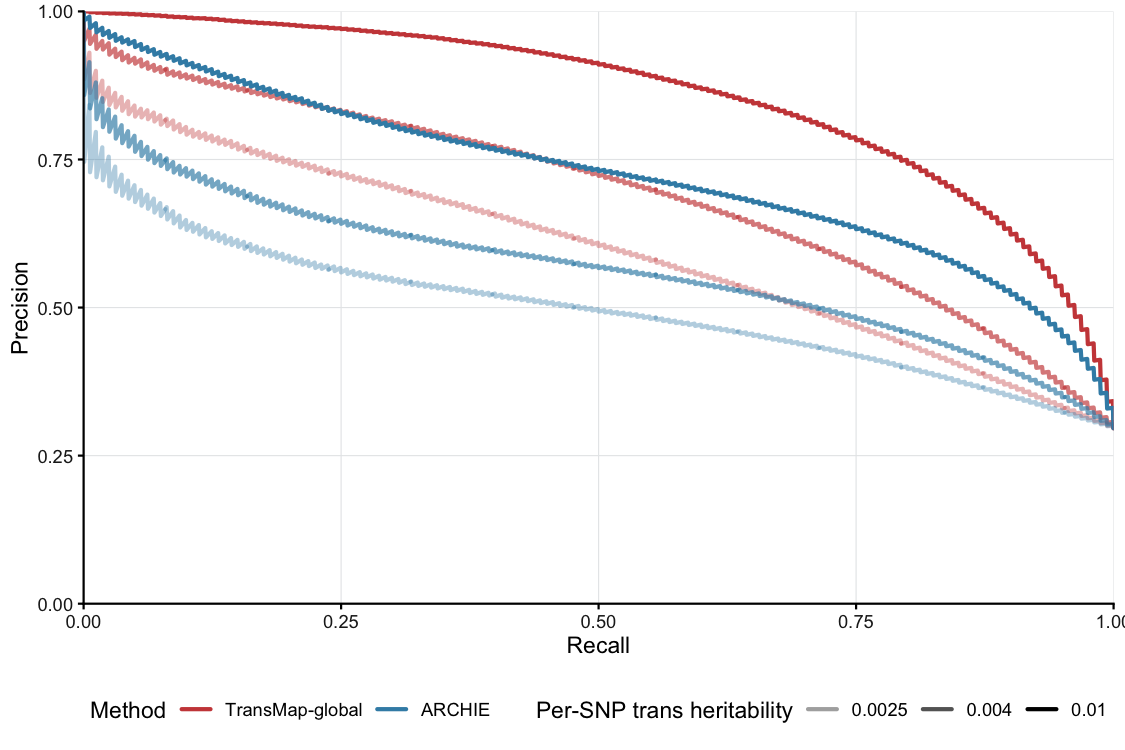

In [2]:
d <- x$curves
d$method <- factor(d$method, levels = c("TransMap-global", "ARCHIE"))
d$effect <- factor(d$phi, levels = c(0.0025, 0.004, 0.01),
                   labels = c("0.0025", "0.004", "0.01"))
p <- ggplot(d, aes(recall, mean_precision, color = method, alpha = effect,
                   group = interaction(method, effect))) +
  geom_line(linewidth = 0.95, lineend = "round") +
  scale_color_manual(values = c("TransMap-global" = "#CC4A48",
                                "ARCHIE" = "#3D8DB4"), name = "Method") +
  scale_alpha_manual(values = c("0.0025" = 0.38, "0.004" = 0.68,
                                "0.01" = 1),
                     name = "Per-SNP trans heritability") +
  scale_x_continuous(limits = c(0, 1), breaks = seq(0, 1, by = 0.25),
                     expand = expansion(mult = c(0, 0))) +
  scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, by = 0.25),
                     expand = expansion(mult = c(0, 0))) +
  labs(x = "Recall", y = "Precision") +
  theme_classic(base_size = 11) +
  theme(panel.grid.major = element_line(color = "#E6E8E9", linewidth = 0.25),
        axis.text = element_text(color = "#202020"),
        legend.position = "bottom")
options(repr.plot.width = 7.5, repr.plot.height = 5, repr.plot.res = 150)
print(p)